In [1]:
import os
import pandas as pd
import numpy as np
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

load_dotenv()

DB_USER = os.getenv("DB_USER")
DB_PASSWORD = os.getenv("DB_PASSWORD")
DB_HOST = os.getenv("DB_HOST")
DB_PORT = os.getenv("DB_PORT")
DB_NAME = os.getenv("DB_NAME")

engine = create_engine(
    f"postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}@"
    f"{DB_HOST}:{DB_PORT}/{DB_NAME}"
)

print("Database engine initialized securely!")

Database engine initialized securely!


In [35]:
with engine.connect() as conn:
    print("PostgreSQL connection successful.")

PostgreSQL connection successful.


In [36]:
tables = pd.read_sql(text("""
SELECT table_name
FROM information_schema.tables
WHERE table_schema = 'retail'
ORDER BY table_name;
"""), engine)
tables


,table_name
0,dim_date
1,dim_demand
2,dim_product
3,dim_region
4,fact_date
5,fact_demand


In [37]:
row_counts = pd.read_sql(text("""
SELECT
    (SELECT COUNT(*) FROM retail.fact_demand) AS fact_rows,
    (SELECT COUNT(*) FROM retail.dim_product) AS product_rows,
    (SELECT COUNT(*) FROM retail.dim_region) AS region_rows;
"""), engine)
row_counts


,fact_rows,product_rows,region_rows
0,0,0,0


In [38]:
from sqlalchemy import text
with engine.connect() as conn:
    conn.execute(text("TRUNCATE TABLE retail.dim_region CASCADE;"))
    conn.commit()

In [39]:
region_df = pd.read_csv("files/Synthetic_Demand_Forecasting_Dataset_50K/Dim_Region.csv")

region_df = region_df[
    ["Region", "Market_Index", "Market_Cluster"]
].copy()

region_df.columns = [
    "region",
    "market_index",
    "market_cluster"
]

region_df.to_sql(
    "dim_region",
    engine,
    schema="retail",
    if_exists="append",
    index=False
)

print("Regions inserted:", len(region_df))

Regions inserted: 8


In [40]:
from sqlalchemy import text
with engine.connect() as conn:
    conn.execute(text("TRUNCATE TABLE retail.dim_product CASCADE;"))
    conn.commit()

In [42]:
product_df = pd.read_csv("files/Synthetic_Demand_Forecasting_Dataset_50K/Dim_Product.csv")

product_df = product_df[
    ["Product_ID", "Brand", "Category","Base_Price","Unit_Cost"]
].copy()

product_df.columns = [
    "product_id",
    "brand",
    "category",
    "base_price",
    "unit_cost"
]

with engine.begin() as connection:
    product_df.to_sql(
        "dim_product",
        connection,
        schema="retail",
        if_exists="append",
        index=False
    )

print("Products inserted:", len(product_df))

Products inserted: 25


In [43]:
from sqlalchemy import text
with engine.connect() as conn:
    conn.execute(text("TRUNCATE TABLE retail.dim_date CASCADE;"))
    conn.commit()

In [44]:
date_df = pd.read_csv("files/Synthetic_Demand_Forecasting_Dataset_50K/Dim_Date.csv")

date_df = date_df[
    ["Date","Week_Index","Year", "Month","Month_Name","Quarter","Week"]
].copy()

date_df.columns = [
    "date",
    "week_index",
    "year",
    "month",
    "month_name",
    "quarter",
    "week"
]

with engine.begin() as connection:
    date_df.to_sql(
        "fact_date",
        connection,
        schema="retail",
        if_exists="append",
        index=False
    )


print("Dates inserted:", len(date_df))

Dates inserted: 250


In [51]:
from sqlalchemy import text
with engine.connect() as conn:
    conn.execute(text("TRUNCATE TABLE retail.fact_demand CASCADE;"))
    conn.commit()

In [53]:
demand_df = pd.read_csv("files/Synthetic_Demand_Forecasting_Dataset_50K/Fact_Demand_Clean_50K.csv")

demand_df["Date"] = pd.to_datetime(demand_df["Date"]).dt.date

demand_df = demand_df[
    ["Date","Product_ID","Region", "Category","Brand","Product_Tier","Channel","Customer_Segment","Demand_Units","Units_Sold","Lost_Sales_Units","List_Price","Selling_Price","Discount_Pct","Promotion_Flag","Competitor_Price","Competitor_Price_Index","Competitor_Promo_Flag","Unit_Cost","Revenue","Gross_Margin","Opening_Inventory","Inventory_Received","Closing_Inventory","Reorder_Point","Lead_Time_Days","Stockout_Flag","Return_Units","Marketing_Spend","Impressions","Clicks","Conversions","Store_Traffic","Search_Index","Temperature_C","Rainfall_mm","Humidity_Pct","Inflation_Pct","Interest_Rate_Pct","GDP_Growth_Pct","Consumer_Confidence","Fuel_Price","Supplier_Reliability","Supplier_Delay_Flag","Campaign_ID","Holiday_Flag","Festival_Flag"]
].copy()

demand_df.columns = [
    "date", "product_id", "region", "category", "brand", "product_tier",
    "channel", "customer_segment", "demand_units", "units_sold",
    "lost_sales_units", "list_price", "selling_price", "discount_pct",
    "promotion_flag", "competitor_price", "competitor_price_index",
    "competitor_promo_flag", "unit_cost", "revenue", "gross_margin",
    "opening_inventory", "inventory_recieved", "closing_inventory",
    "reorder_point", "lead_time_days", "stockout_flag", "return_unit",
    "marketing_spend", "impressions", "clicks", "conversions",
    "store_traffic", "search_index", "temperature_c", "rainfall_mm",
    "humidity_pct", "inflation_pct", "interest_rate_pct", "gdp_growth_pct",
    "consumer_confidence", "fuel_price", "supplier_reliability",
    "supplier_delay_flag", "campaign_id", "holiday_flag", "festival_flag"
]

with engine.begin() as connection:
    demand_df.to_sql(
        "fact_demand",
        connection,
        schema="retail",
        if_exists="append",
        index=False
    )

print("Data inserted successfully:", len(demand_df))

Data inserted successfully: 50000


In [54]:
query = """
SELECT *
FROM retail.fact_demand
ORDER BY date, product_id, region;
"""

df = pd.read_sql(query, engine)

df["date"] = pd.to_datetime(df["date"])

df.shape

(50000, 47)

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

In [55]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
date,50000,2023-05-25 11:59:59.999999744,2021-01-04 00:00:00,2022-03-14 00:00:00,2023-05-25 12:00:00,2024-08-05 00:00:00,2025-10-13 00:00:00,NaN
demand_units,50000.0,172.241,4.0,52.0,111.0,245.0,1942.0,166.82468
units_sold,50000.0,170.56268,4.0,52.0,110.0,243.0,1693.0,163.222491
lost_sales_units,50000.0,1.67832,0.0,0.0,0.0,0.0,948.0,17.249262
list_price,50000.0,7865.70503,353.79,1060.515,4268.56,10321.25,33637.84,8484.957762
selling_price,50000.0,7441.920754,262.32,1010.205,4073.585,9923.585,32843.99,8057.55505
discount_pct,50000.0,5.414984,0.01,2.25,3.39,5.01,29.66,5.885283
promotion_flag,50000.0,0.14416,0.0,0.0,0.0,0.0,1.0,0.351255
competitor_price,50000.0,7894.300122,303.55,1064.8425,4277.835,10396.4825,35245.34,8526.991766
competitor_price_index,50000.0,1.003723,0.85,0.984,1.007,1.029,1.12,0.037778


Weekly Demand

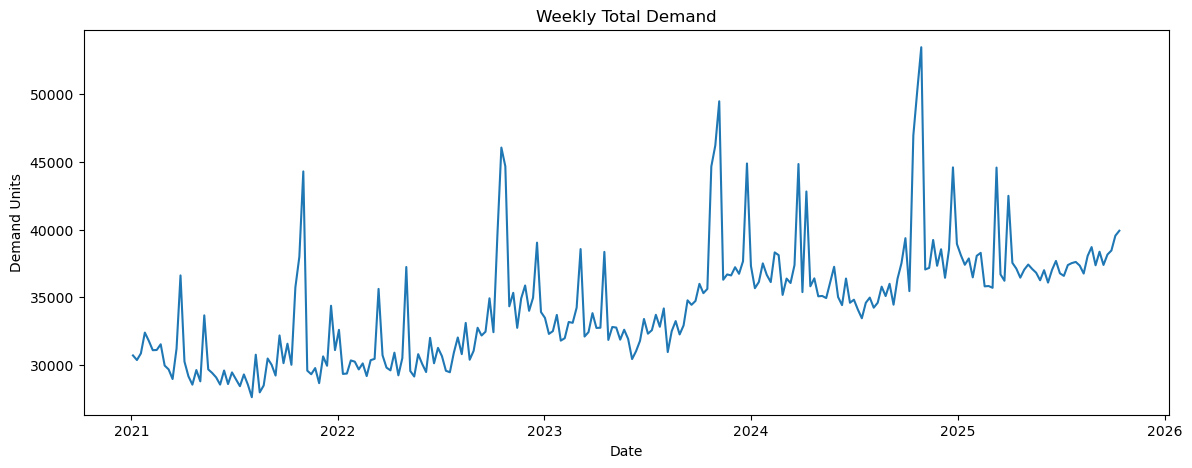

In [59]:
weekly = (
    df.groupby("date")["demand_units"]
      .sum()
)

plt.figure(figsize=(14,5))
plt.plot(weekly)
plt.title("Weekly Total Demand")
plt.xlabel("Date")
plt.ylabel("Demand Units")
plt.show()

Mounthly Seasonality

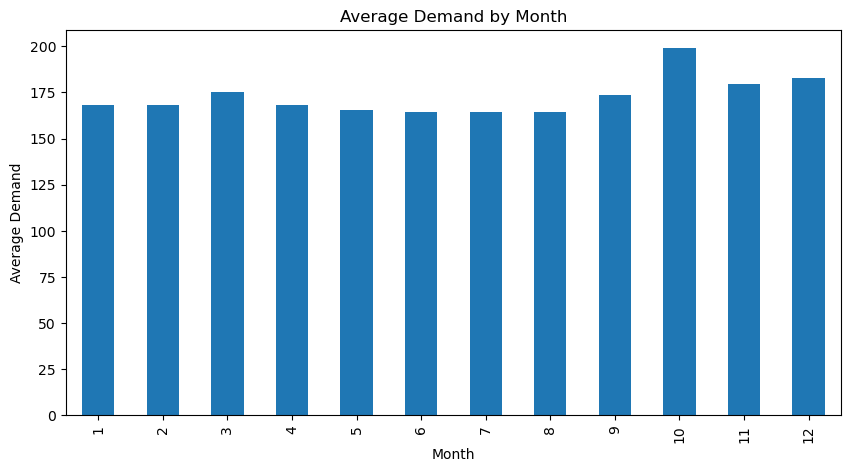

In [61]:
monthly = (
    df.groupby(df["date"].dt.month)["demand_units"]
      .mean()
)

plt.figure(figsize=(10,5))
monthly.plot(kind="bar")
plt.title("Average Demand by Month")
plt.xlabel("Month")
plt.ylabel("Average Demand")
plt.show()

Week-of-year seaasonality

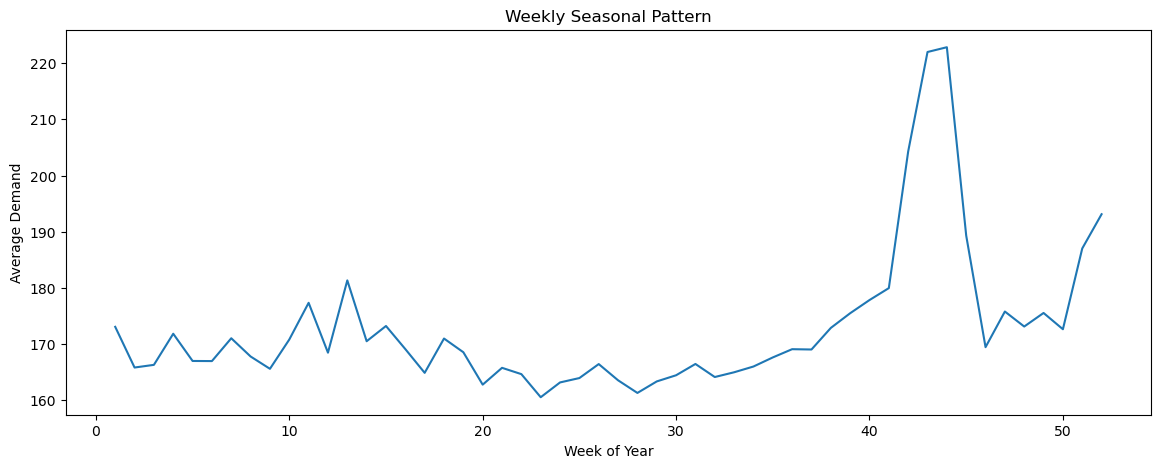

In [62]:
df["week_of_year"] = df["date"].dt.isocalendar().week.astype(int)

weekly_seasonality = (
    df.groupby("week_of_year")["demand_units"]
      .mean()
)

plt.figure(figsize=(14,5))
plt.plot(
    weekly_seasonality.index,
    weekly_seasonality.values
)
plt.title("Weekly Seasonal Pattern")
plt.xlabel("Week of Year")
plt.ylabel("Average Demand")
plt.show()

Festival Lift

In [63]:
df.groupby("festival_flag")["demand_units"].mean()

festival_flag
0    167.746406
1    210.963654
Name: demand_units, dtype: float64

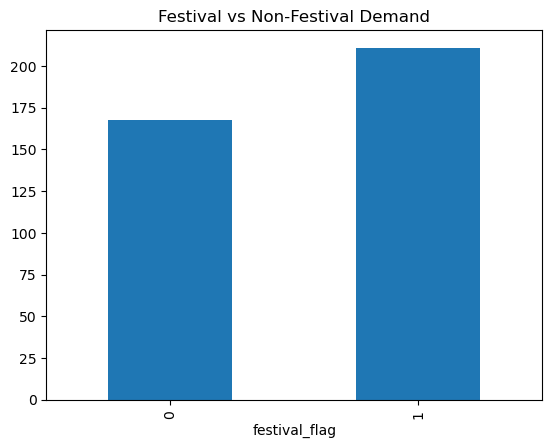

In [65]:
festival_lift = (
    df.groupby("festival_flag")["demand_units"]
      .mean()
)

festival_lift.plot(kind="bar")
plt.title("Festival vs Non-Festival Demand")
plt.show()

Holiday Lift

In [73]:
df.groupby("Holiday_Flag")["Demand_Units"].mean()

Holiday_Flag
0    171.573899
1    178.825000
Name: Demand_Units, dtype: float64

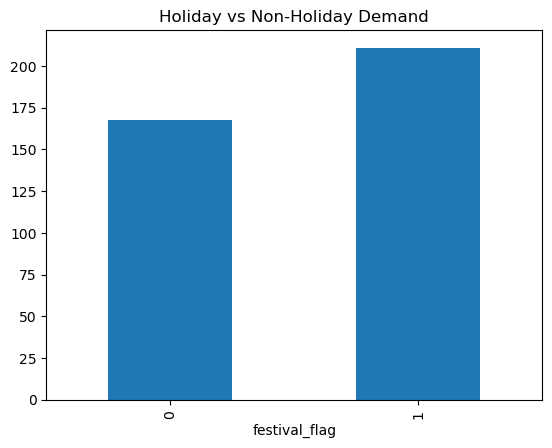

In [66]:
holiday_lift = (
    df.groupby("holiday_flag")["demand_units"]
      .mean()
)

festival_lift.plot(kind="bar")
plt.title("Holiday vs Non-Holiday Demand")
plt.show()

Discount VS Demand

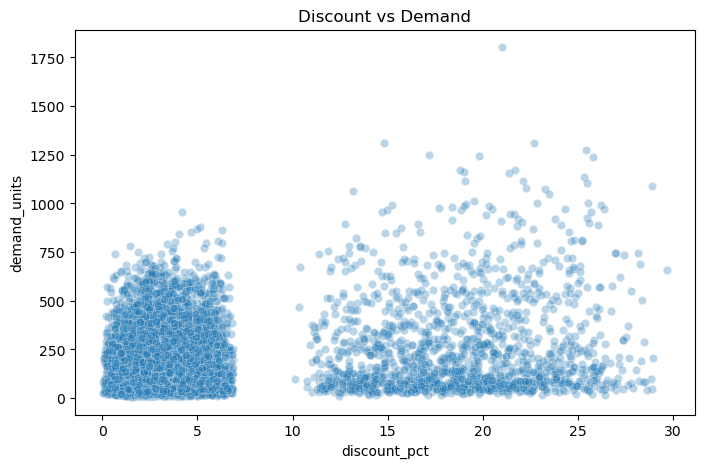

In [67]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df.sample(min(10000, len(df))),
    x="discount_pct",
    y="demand_units",
    alpha=0.3
)

plt.title("Discount vs Demand")
plt.show()

Price Relationship

In [70]:
df["relative_price"] = (
    df["selling_price"] /
    df["competitor_price"]
)

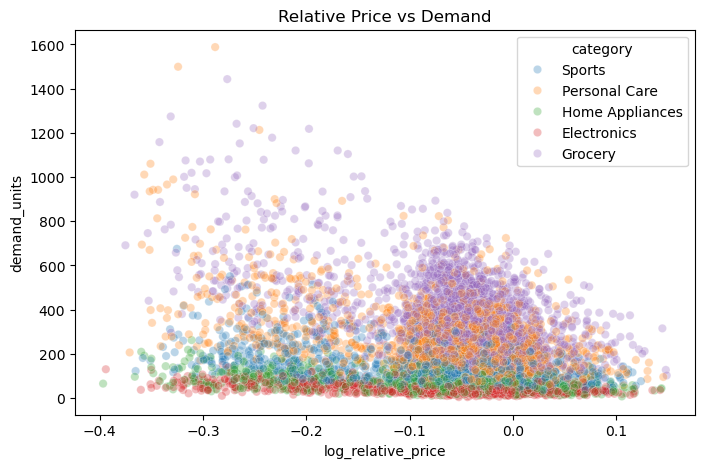

In [73]:
df["log_relative_price"] = np.log(
    df["relative_price"]
)

plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df.sample(min(10000, len(df))),
    x="log_relative_price",
    y="demand_units",
    hue="category",
    alpha=0.3
)

plt.title("Relative Price vs Demand")
plt.show()

Category Caomparison

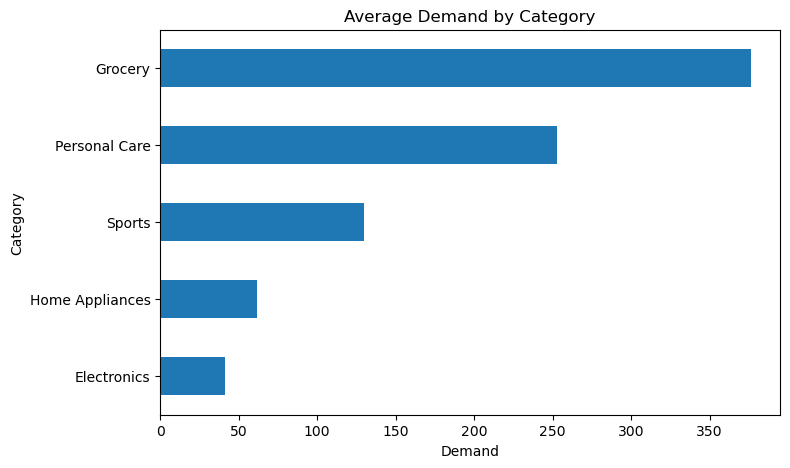

In [79]:
category_demand = (
    df.groupby("category")["demand_units"]
      .mean()
      .sort_values()
)

category_demand.plot(kind="barh", figsize=(9,5))

plt.title("Average Demand by Category")
plt.xlabel("Demand")
plt.show()

Region Comparison

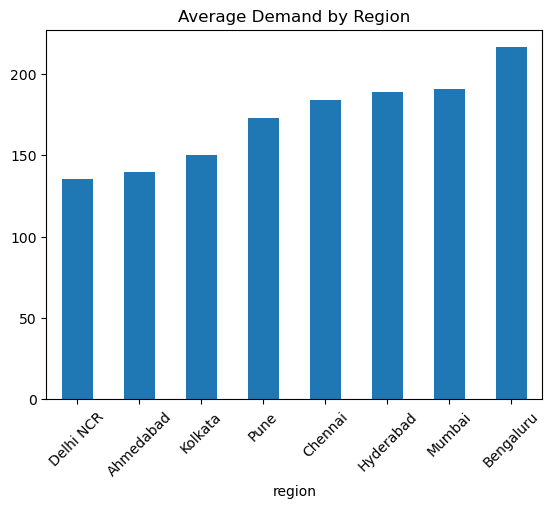

In [74]:
region_demand = (
    df.groupby("region")["demand_units"]
      .mean()
      .sort_values()
)

region_demand.plot(kind="bar")

plt.title("Average Demand by Region")
plt.xticks(rotation=45)
plt.show()

Stockouts and lost sales

In [75]:
df.groupby("stockout_flag")[
    "lost_sales_units"
].mean()

stockout_flag
0     0.000000
1    54.847059
Name: lost_sales_units, dtype: float64

In [76]:
stockout_summary = (
    df.groupby("region")
      .agg(
          stockout_rate=("stockout_flag", "mean"),
          lost_sales=("lost_sales_units", "sum")
      )
      .sort_values("lost_sales", ascending=False)
)

stockout_summary

,stockout_rate,lost_sales
region,,
Mumbai,0.03120,13640.0
Hyderabad,0.02976,11525.0
Bengaluru,0.02560,11006.0
Chennai,0.03504,10848.0
Kolkata,0.03440,10474.0
Ahmedabad,0.03344,10041.0
Pune,0.02704,8848.0
Delhi NCR,0.02832,7534.0


Correlation Heatmap

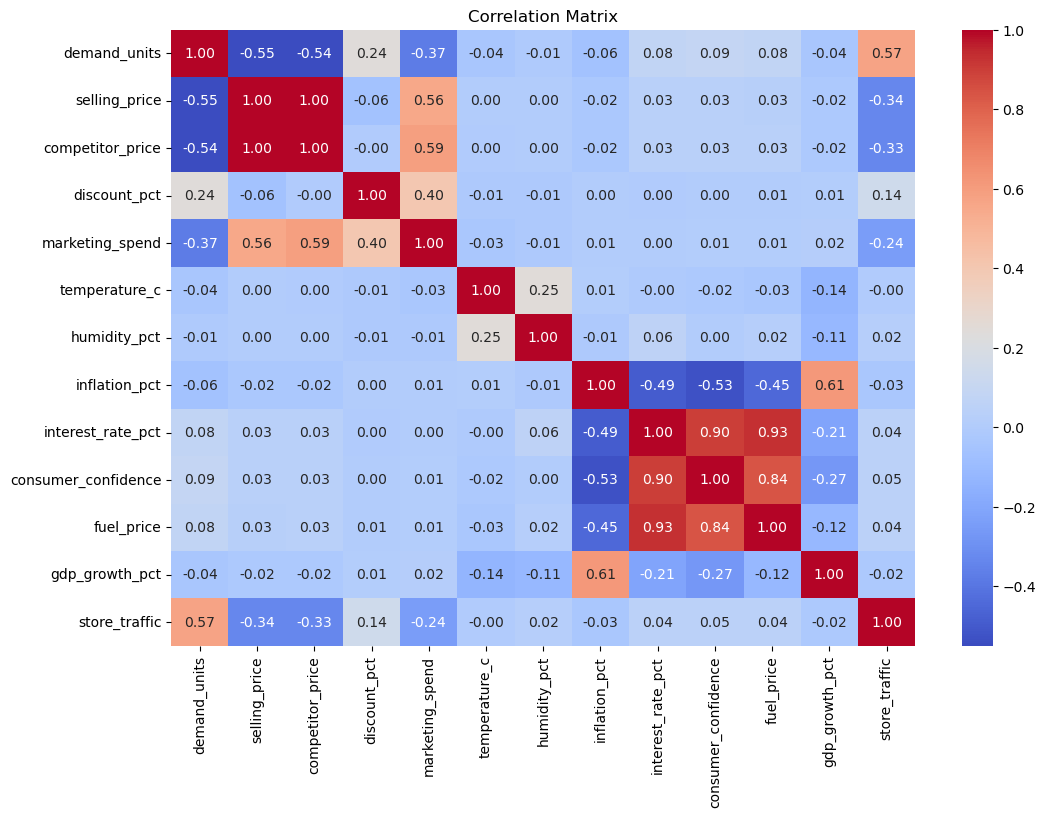

In [80]:
numeric_cols = [
    "demand_units",
    "selling_price",
    "competitor_price",
    "discount_pct",
    "marketing_spend",
    "temperature_c",
    "humidity_pct",
    "inflation_pct",        
    "interest_rate_pct",  
    "consumer_confidence",
    "fuel_price",
    "gdp_growth_pct",      
    "store_traffic"        
]

plt.figure(figsize=(12, 8))

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.show()